# Problem Statement 2: 

A university campus consists of several locations connected by roads. 
Each road has a travel  cost. 
A heuristic value representing the estimated cost from each location to the destination is  also provided. 
 
The objective is to find a route from a given starting location to a target location using informed search. 

In [25]:
import heapq
import time
from collections import defaultdict


## Campus Graph 
 
The edges are bidirectional.

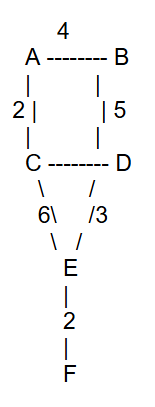

In [26]:
from PIL import Image

image = Image.open("sample_graph_1.png")
display(image)

### Edge Costs 

Edge  Cost 
1. A – B  4 
2. A – C  2 
3. B – D  5 
4. C – D  3 
5. C – E  6 
6. D – E  3 
7. E – F  2

### Heuristic Values 

Node  h(n) 
1. A  7
2. B  8
3. C  5
4. D  4
5. E  2
6. F  0

### Goal: F

## Objective 
 
Find a path from A to F using: 
1. Greedy Best-First Search     (Done by another teammate)
2. A* Search 

### Input Format (from a text file)

Instead of typing values in with `input()`, the graph, heuristics, start node, and goal node are now read from a plain text file (this is the approach my teammate used for GBFS).

File format:
1. First line   - `N M`
2. Next M lines - `U V C` (U and V = connected nodes ; C = edge cost)
3. Next line    - `S G` (Start and Goal)
4. Next N lines - `Node Heuristic`


In [27]:
def read_graph(text):
    lines = text.strip("\n").split("\n")
    idx = 0
    N, M = map(int, lines[idx].split())
    idx += 1

    graph = defaultdict(list)   # node -> list of (neighbor, cost)
    for _ in range(M):
        u, v, c = lines[idx].split()
        c = int(c)
        graph[u].append((v, c))
        graph[v].append((u, c))   # bidirectional
        idx += 1

    start, goal = lines[idx].split()
    idx += 1

    heuristic = {}
    for _ in range(N):
        parts = lines[idx].split()
        node, h = parts[0], int(parts[1])
        heuristic[node] = h
        idx += 1

    return graph, heuristic, start, goal

### For Greedy Best-First Search: 
 
f(n) = h(n)
 
h(n) = estimated cost to goal

In [28]:
def reconstruct_path(parent, goal):
    path = [goal]
    while path[-1] in parent:
        path.append(parent[path[-1]])
    path.reverse()
    return path

In [29]:
# f(n) = h(n). Priority queue ordered purely by heuristic value.
# heap entries: (f, node, g_cost_so_far)
def greedy_best_first(graph, heuristic, start, goal):
    start_time = time.perf_counter()

    heap = [(heuristic[start], 0, start, 0)]
    visited = set()
    parent = {}
    nodes_expanded = 0
    counter = 0

    while heap:
        _, _, node, cost = heapq.heappop(heap)

        if node in visited:
            continue

        visited.add(node)
        nodes_expanded += 1

        if node == goal:
            elapsed = time.perf_counter() - start_time
            path = reconstruct_path(parent, goal)
            return True, path, cost, nodes_expanded, elapsed

        for neighbor, edge_cost in graph[node]:
            if neighbor not in visited:
                if neighbor not in parent:
                    parent[neighbor] = node

                counter += 1
                heapq.heappush(
                    heap,
                    (heuristic[neighbor], counter, neighbor,
                     cost + edge_cost)
                )

    elapsed = time.perf_counter() - start_time
    return False, [], 0, nodes_expanded, elapsed


In [30]:
def print_result(result):
    found, path, cost, nodes_expanded, elapsed = result

    print("Algorithm: Greedy Best-First Search")
    print("Path Found:", "Yes" if found else "No")

    if found:
        print("Path:", " → ".join(path))
        print("Total Cost =", cost)
        
    else:
        print("Path: None")
        print("Total Cost = 0")

    print("Nodes Expanded =", nodes_expanded)
    print("Execution Time = ", elapsed)

### Search Functions (A* Search)
 
f(n) = g(n) + h(n) 
 
g(n) = cost from start to current node 
h(n) = estimated cost to goal

In [31]:
def a_star(graph, heuristic, start, end):
    
    # cost from start to each node
    g = {start: 0}
    
    # remember how we reached each node
    parent = {start: None}
    
    # nodes waiting ro be explored
    open_set = []
    
    # A node is expanded 
    #       when we take it out of priority queue
    #       and examine its neighbours
    nodes_expanded = 0
    
    # Push the starting vertex in the min-heap
    heapq.heappush(open_set, (heuristic[start], start))
    
    # Start counting time passed
    start_time = time.perf_counter()
    
    # ---- WHILE NODES ARE WAITING ---- # 
    while open_set:
        
        # Pop the element with minimum value 
        #           (which is minimum f - 
        #               minimum predicted distance)
        f_current, current = heapq.heappop(open_set)
        
        # Ignore an outdated entry in the heap
        if f_current != g[current] + heuristic[current]:
            continue
        
        if current == end:
            break
        
        # We have expanded a node
        nodes_expanded += 1
        
        # We are checking each neighbours
        for neighbour, cost in graph[current]:
            
            # calculate possible g's for possible next node
            new_g = g[current] + cost
            
            # If this is the first time I visited the neighbour?
            # Or, if this path to reach g was cheaper than what I had stored earlier for later use?
            if neighbour not in g or new_g < g[neighbour]:
                g[neighbour] = new_g                        # set g
                parent[neighbour] = current                 # set parent
                f = new_g + heuristic[neighbour]            # set new f
                heapq.heappush(open_set, (f, neighbour))    # push it into heap
        
    # Stop Counting Time
    execution_time = time.perf_counter() - start_time
        
    path = []
    current = end
        
    # If We never reached end node, it means there is no path
    if end not in parent:
        return {
            "path_found": False,
            "path": [],
            "total_cost": None,
            "nodes_expanded": nodes_expanded,
            "execution_time": execution_time
        }
        
    # Get the path from parent dictionary
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()
        
    # Total Cost
    total_cost = g[end]
        
    return {
        "path_found": True,
        "path": path,
        "total_cost": total_cost,
        "nodes_expanded": nodes_expanded,
        "execution_time": execution_time
    }


In [32]:
def run_astar(graph, heuristic, start, end):
    result = a_star(graph, heuristic, start, end)
    print("\nA Star Algorithm")
    print("Path Found:", result["path_found"])
    print("Path:", " → ".join(result["path"]))
    print("Total Cost =", result["total_cost"])
    print("Nodes Expanded =", result["nodes_expanded"])
    print("Execution Time =", result["execution_time"])

### Constraints 
 
1. 2 ≤ N ≤ 100 
2. 1 ≤ M ≤ N(N-1)/2 
3. Edge costs are positive 
4. h(n) ≥ 0 
5. Exactly one start and goal node 
6. Graph edges are bidirectional

## Test Cases

### Test Case 1 

6 7 

1. A B 4 
2. A C 2 
3. B D 5 
4. C D 3 
5. C E 6 
6. D E 3 
7. E F 2 

A F 

1. A 7 
2. B 8 
3. C 5 
4. D 4 
5. E 2 
6. F 0 

In [33]:
with open("test_case_1.txt", "w") as f:
    f.write("""6 7
A B 4
A C 2
B D 5
C D 3
C E 6
D E 3
E F 2
A F
A 7
B 8
C 5
D 4
E 2
F 0""")


In [34]:
with open("test_case_1.txt", "r") as f:
    inp = f.read()

graph, heuristic, start, goal = read_graph(inp)

# Greedy Best-First Search
gbfs_result = greedy_best_first(graph, heuristic, start, goal)
print_result(gbfs_result)
print()

# A* Search
run_astar(graph, heuristic, start, goal)


Algorithm: Greedy Best-First Search
Path Found: Yes
Path: A → C → E → F
Total Cost = 10
Nodes Expanded = 4
Execution Time =  1.109996810555458e-05


A Star Algorithm
Path Found: True
Path: A → C → E → F
Total Cost = 10
Nodes Expanded = 4
Execution Time = 8.800067007541656e-06


#### Sample Output (A* Search )
1. Path Found: Yes 
2. Path: A → C → D → E → F 
3. Total Cost = 10 
4. Nodes Expanded = N 

### Test Case 2

A second graph where Greedy Best-First Search and A* choose different routes, so we can see that Greedy Search does not necessarily find the optimal path.

5 5

1. S A 1
2. S B 2
3. A G 10
4. B C 2
5. C G 1

S G

1. S 6
2. A 1
3. B 5
4. C 3
5. G 0

Here `h(A) = 1` looks very promising, so GBFS rushes toward `A` and then pays a heavy price on the expensive `A–G` edge (cost 10). A* balances the heuristic against the actual cost travelled so far, so it instead explores `B → C → G`, which turns out to be the truly cheapest route.


In [35]:
with open("test_case_2.txt", "w") as f:
    f.write("""5 5
S A 1
S B 2
A G 10
B C 2
C G 1
S G
S 6
A 1
B 5
C 3
G 0""")


In [36]:
with open("test_case_2.txt", "r") as f:
    inp = f.read()

graph2, heuristic2, start2, goal2 = read_graph(inp)

# Greedy Best-First Search
gbfs_result2 = greedy_best_first(graph2, heuristic2, start2, goal2)
print_result(gbfs_result2)
print()

# A* Search
run_astar(graph2, heuristic2, start2, goal2)


Algorithm: Greedy Best-First Search
Path Found: Yes
Path: S → A → G
Total Cost = 11
Nodes Expanded = 3
Execution Time =  1.3699987903237343e-05


A Star Algorithm
Path Found: True
Path: S → B → C → G
Total Cost = 5
Nodes Expanded = 4
Execution Time = 8.200062438845634e-06


## Additional Requirements

### Report
For both algorithms report: 
 
1. Path Found 
2. Path 
3. Total Path Cost 
4. Nodes Expanded 
5. Execution Time 

### Comparison  
Compare Greedy Best-First Search and A* based on: 
 
1. Path cost 
2. Number of states explored 
3. Execution time 
4. Optimality 
5. Effectiveness of the heuristic used 

**Observed results:**

| | GBFS (Test 1) | A* (Test 1) | GBFS (Test 2) | A* (Test 2) |
|---|---|---|---|---|
| Path Found | Yes | Yes | Yes | Yes |
| Path | A → C → E → F | A → C → E → F | S → A → G | S → B → C → G |
| Total Path Cost | 10 | 10 | 11 | 5 |
| Nodes Expanded | 4 | 4 | 3 | 4 |
| Optimal? | Yes (tied optimum) | Yes | **No** | Yes |

- **Path cost:** In Test Case 1 both algorithms happen to land on an equally cheap path. In Test Case 2, GBFS's path costs more than double A*'s path (11 vs 5).
- **States explored:** GBFS can expand fewer nodes than A* (3 vs 4 in Test 2) because it charges straight toward whatever looks closest to the goal, ignoring cost so far.
- **Execution time:** Both algorithms are essentially instantaneous on graphs this small; any timing difference is noise, not a meaningful signal at this scale.
- **Optimality:** A* is guaranteed optimal here because the heuristic values used are admissible (never overestimate the true remaining cost). GBFS has no such guarantee — Test Case 2 demonstrates it picking a strictly worse path because it never accounts for the cost already paid to reach a node.
- **Effectiveness of the heuristic:** The heuristic worked well for A* in both cases because it stayed admissible. For GBFS, the same heuristic values (specifically `h(A) = 1`, a very optimistic estimate) actively misled the search in Test Case 2 by hiding the expensive `A–G` edge.
